In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/raw/NIH_ChestXray14/Data_Entry_2017.csv"
)

print("Shape:", df.shape)

df.head()

Shape: (112120, 11)


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168


In [2]:
df.columns.to_list()

['Image Index',
 'Finding Labels',
 'Follow-up #',
 'Patient ID',
 'Patient Age',
 'Patient Sex',
 'View Position',
 'OriginalImage[Width',
 'Height]',
 'OriginalImagePixelSpacing[x',
 'y]']

In [3]:
df.columns = [
    "image_index",
    "finding_labels",
    "follow_up",
    "patient_id",
    "patient_age",
    "patient_sex",
    "view_position",
    "image_width",
    "image_height",
    "pixel_spacing_x",
    "pixel_spacing_y"
]

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 11 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   image_index      112120 non-null  object 
 1   finding_labels   112120 non-null  object 
 2   follow_up        112120 non-null  int64  
 3   patient_id       112120 non-null  int64  
 4   patient_age      112120 non-null  int64  
 5   patient_sex      112120 non-null  object 
 6   view_position    112120 non-null  object 
 7   image_width      112120 non-null  int64  
 8   image_height     112120 non-null  int64  
 9   pixel_spacing_x  112120 non-null  float64
 10  pixel_spacing_y  112120 non-null  float64
dtypes: float64(2), int64(5), object(4)
memory usage: 9.4+ MB


In [5]:
CLASSES = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax",
    "Consolidation",
    "Edema",
    "Emphysema",
    "Fibrosis",
    "Pleural_Thickening",
    "Hernia"
]

In [6]:
# Missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
image_index        0
finding_labels     0
follow_up          0
patient_id         0
patient_age        0
patient_sex        0
view_position      0
image_width        0
image_height       0
pixel_spacing_x    0
pixel_spacing_y    0
dtype: int64


In [7]:
# Duplicate images
print("Duplicate images:", df["image_index"].duplicated().sum())

# Unique patients
print("Unique patients:", df["patient_id"].nunique())

# Unique images
print("Unique images:", df["image_index"].nunique())

Duplicate images: 0
Unique patients: 30805
Unique images: 112120


In [8]:
# View positions
print(df["view_position"].value_counts())

# Patient sex
print(df["patient_sex"].value_counts())

# Patient age
print(df["patient_age"].describe())

view_position
PA    67310
AP    44810
Name: count, dtype: int64
patient_sex
M    63340
F    48780
Name: count, dtype: int64
count    112120.000000
mean         46.626365
std          16.602680
min           0.000000
25%          34.000000
50%          49.000000
75%          59.000000
max          95.000000
Name: patient_age, dtype: float64


In [9]:
label_counts = (
    df["finding_labels"]
    .str.split("|")
    .explode()
    .value_counts()
)

print(label_counts)

finding_labels
No Finding            60361
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
Name: count, dtype: int64


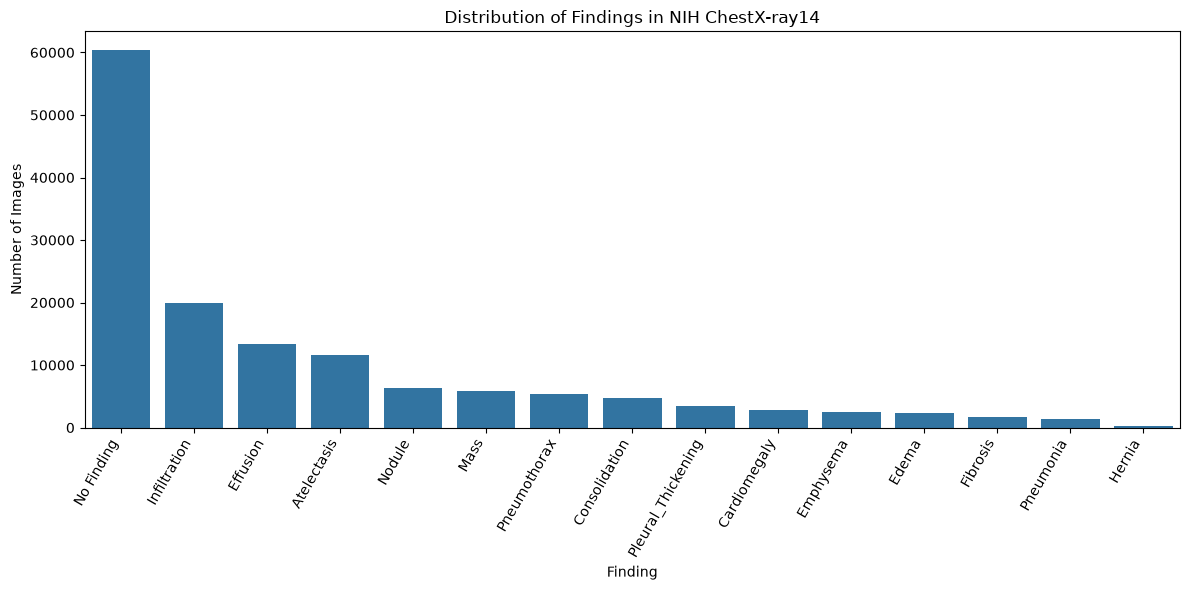

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.xticks(rotation=60, ha="right")
plt.title("Distribution of Findings in NIH ChestX-ray14")
plt.xlabel("Finding")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

In [11]:
df["num_labels"] = (
    df["finding_labels"]
    .str.split("|")
    .apply(len)
)

print(df["num_labels"].value_counts().sort_index())

num_labels
1    91324
2    14306
3     4856
4     1247
5      301
6       67
7       16
8        1
9        2
Name: count, dtype: int64


In [12]:
for label in CLASSES:
    df[label] = df["finding_labels"].apply(lambda x: int(label in x.split("|")))

In [13]:
df.head()

,image_index,finding_labels,follow_up,patient_id,patient_age,patient_sex,view_position,image_width,image_height,pixel_spacing_x,...,Mass,Nodule,Pneumonia,Pneumothorax,Consolidation,Edema,Emphysema,Fibrosis,Pleural_Thickening,Hernia
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,...,0,0,0,0,0,0,0,0,0,0
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,...,0,0,0,0,0,0,1,0,0,0
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,...,0,0,0,0,0,0,0,0,0,0
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,...,0,0,0,0,0,0,0,0,0,0
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,...,0,0,0,0,0,0,0,0,0,1


In [14]:
print(df[CLASSES].sum().sort_values(ascending=False))

Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
dtype: int64


In [15]:
from pathlib import Path

IMAGE_DIR = Path(
    "../data/raw/NIH_ChestXray14/images"
)

available_images = set(
    p.name for p in IMAGE_DIR.glob("*.png")
)

df_subset = df[
    df["image_index"].isin(available_images)
].copy()

print("Available images:", len(df_subset))
print("Unique patients:", df_subset["patient_id"].nunique())

Available images: 112120
Unique patients: 30805


In [16]:
from sklearn.model_selection import GroupShuffleSplit

gss1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss1.split(
        df_subset,
        groups=df_subset["patient_id"]
    )
)

train_df = df_subset.iloc[train_idx].copy()
temp_df = df_subset.iloc[temp_idx].copy()

gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(
        temp_df,
        groups=temp_df["patient_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

In [17]:
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (78566, 26)
Validation: (16106, 26)
Test: (17448, 26)


In [18]:
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

print("Train ∩ Validation:", len(train_patients & val_patients))

print("Train ∩ Test:", len(train_patients & test_patients))

print("Validation ∩ Test:", len(val_patients & test_patients))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [19]:
split_distribution = pd.DataFrame({
    "Train": train_df[CLASSES].mean(),
    "Validation": val_df[CLASSES].mean(),
    "Test": test_df[CLASSES].mean()
})

print(split_distribution)

                       Train  Validation      Test
Atelectasis         0.104244    0.100025  0.100757
Cardiomegaly        0.024069    0.024152  0.028427
Effusion            0.120128    0.114305  0.116804
Infiltration        0.176514    0.182106  0.177270
Mass                0.054222    0.047312  0.043558
Nodule              0.056411    0.057122  0.056110
Pneumonia           0.012665    0.014032  0.012036
Pneumothorax        0.047985    0.043276  0.047856
Consolidation       0.041086    0.041475  0.044188
Edema               0.020747    0.021048  0.019143
Emphysema           0.021205    0.023470  0.027052
Fibrosis            0.014714    0.015708  0.015876
Pleural_Thickening  0.030280    0.029182  0.030720
Hernia              0.002011    0.002173  0.001949


In [20]:
from pathlib import Path

SPLIT_DIR = Path("../data/splits")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(SPLIT_DIR / "validation.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

In [21]:
from medical_imaging_ai.preprocessing import create_dataset
from medical_imaging_ai.paths import IMAGE_DIR

train_ds = create_dataset(
    train_df,
    IMAGE_DIR,
    batch_size=32,
    training=True
)

val_ds = create_dataset(
    val_df,
    IMAGE_DIR,
    batch_size=32,
    training=False
)

test_ds = create_dataset(
    test_df,
    IMAGE_DIR,
    batch_size=32,
    training=False
)

2026-11-19 15:17:25.417873: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-11-19 15:17:25.417903: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-11-19 15:17:25.417908: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-11-19 15:17:25.417921: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-19 15:17:25.417931: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [24]:
import tensorflow as tf

images, labels = next(iter(train_ds))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("Image range:", tf.reduce_min(images).numpy(),
      tf.reduce_max(images).numpy())

Image shape: (32, 224, 224, 3)
Label shape: (32, 14)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'float32'>
Image range: -2.117904 2.64


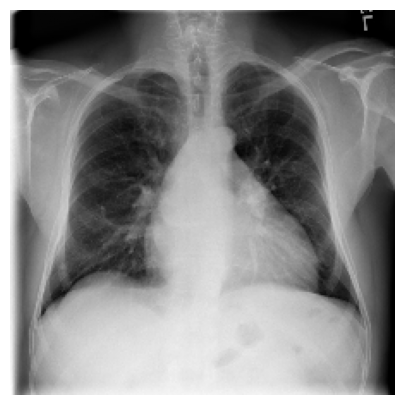

In [25]:

from medical_imaging_ai.constants import IMAGE_SIZE

def visualize_image(image_path):

    image = tf.io.read_file(str(image_path))

    image = tf.io.decode_png(
        image,
        channels=1
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    plt.figure(figsize=(5, 5))

    plt.imshow(
        tf.squeeze(image),
        cmap="gray"
    )

    plt.axis("off")
    plt.show()


visualize_image(
    IMAGE_DIR / train_df.iloc[0]["image_index"]
)

In [26]:
from medical_imaging_ai.model import build_model

model = build_model()

model.summary()

Model: "chest_xray_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 14)             │         3,598 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,303,502 (27.86 MB)

 Trainable params: 265,998 (1.01 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [27]:
from tensorflow import keras

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=keras.losses.BinaryCrossentropy(),

    metrics=[
        keras.metrics.AUC(
            name="roc_auc",
            multi_label=True,
            num_labels=len(CLASSES)
        ),
        keras.metrics.AUC(
            name="pr_auc",
            curve="PR",
            multi_label=True,
            num_labels=len(CLASSES)
        )
    ]
)

In [28]:
from medical_imaging_ai.paths import PROJECT_ROOT

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model.save(MODEL_DIR / "densenet121_initial.keras")

In [29]:
import tensorflow as tf
import keras
import platform

print("Machine:", platform.machine())
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

Machine: arm64
TensorFlow: 2.17.0
Keras: 3.5.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [30]:
class_counts = train_df[CLASSES].sum().sort_values()

print(class_counts)

Hernia                  158
Pneumonia               995
Fibrosis               1156
Edema                  1630
Emphysema              1666
Cardiomegaly           1891
Pleural_Thickening     2379
Consolidation          3228
Pneumothorax           3770
Mass                   4260
Nodule                 4432
Atelectasis            8190
Effusion               9438
Infiltration          13868
dtype: int64


In [32]:
# Small development subsets
train_debug = train_df.sample(
    n=10000,
    random_state=42
)

val_debug = val_df.sample(
    n=2000,
    random_state=42
)

In [33]:
train_debug_ds = create_dataset(
    train_debug,
    IMAGE_DIR,
    batch_size=32,
    training=True
)

val_debug_ds = create_dataset(
    val_debug,
    IMAGE_DIR,
    batch_size=32,
    training=False
)

In [34]:
from medical_imaging_ai.train import get_callbacks

history = model.fit(
    train_debug_ds,
    validation_data=val_debug_ds,
    epochs=2,
    callbacks=get_callbacks()
)

Epoch 1/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - loss: 0.1752 - pr_auc: 0.0982 - roc_auc: 0.6652
Epoch 1: val_loss improved from inf to 0.16887, saving model to /Users/ayushsinghsongara/Documents/Development/GitHub/medical-imaging-ai/models/best_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 50s 160ms/step - loss: 0.1752 - pr_auc: 0.0982 - roc_auc: 0.6652 - val_loss: 0.1689 - val_pr_auc: 0.1276 - val_roc_auc: 0.7227 - learning_rate: 0.0010
Epoch 2/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - loss: 0.1744 - pr_auc: 0.1015 - roc_auc: 0.6749
Epoch 2: val_loss did not improve from 0.16887
313/313 ━━━━━━━━━━━━━━━━━━━━ 44s 141ms/step - loss: 0.1744 - pr_auc: 0.1015 - roc_auc: 0.6750 - val_loss: 0.1695 - val_pr_auc: 0.1246 - val_roc_auc: 0.7131 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 1.


In [35]:
import matplotlib.pyplot as plt

def plot_training_history(history):

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    axes[0].plot(history.history["loss"], label="Train Loss")
    axes[0].plot(history.history["val_loss"], label="Validation Loss")
    axes[0].set_title("Training vs Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Binary Crossentropy")
    axes[0].legend()

    # AUC
    axes[1].plot(history.history["roc_auc"], label="Train ROC-AUC")
    axes[1].plot(history.history["val_roc_auc"], label="Validation ROC-AUC")
    axes[1].plot(history.history["pr_auc"], label="Train PR-AUC")
    axes[1].plot(history.history["val_pr_auc"], label="Validation PR-AUC")
    axes[1].set_title("AUC Metrics")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

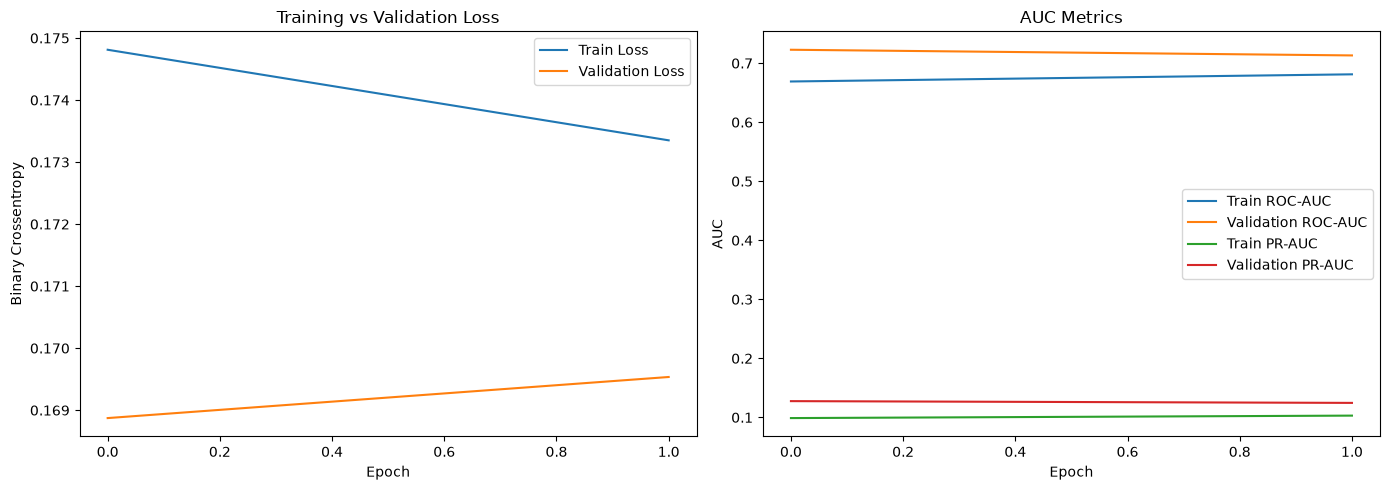

In [36]:
plot_training_history(history)

In [37]:
import json

history_path = PROJECT_ROOT / "models" / "training_history.json"

with open(history_path, "w") as f:
    json.dump(history.history, f, indent=4)

In [38]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Generate predictions
y_pred = model.predict(val_debug_ds)

# Extract ground-truth labels
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_debug_ds
])

print("Actual labels:", y_true.shape)
print("Predictions:", y_pred.shape)

63/63 ━━━━━━━━━━━━━━━━━━━━ 23s 204ms/step
Actual labels: (2000, 14)
Predictions: (2000, 14)


2026-11-20 10:57:54.571103: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [39]:
results = []

for i, disease in enumerate(CLASSES):

    actual = y_true[:, i]
    predicted = y_pred[:, i]

    positive_count = int(actual.sum())

    # Both positive and negative samples are required
    # for ROC-AUC calculation.
    if len(np.unique(actual)) < 2:
        roc_auc = np.nan
    else:
        roc_auc = roc_auc_score(actual, predicted)

    pr_auc = average_precision_score(
        actual,
        predicted
    )

    results.append({
        "Disease": disease,
        "Positive Samples": positive_count,
        "ROC-AUC": roc_auc,
        "Average Precision": pr_auc
    })

evaluation_df = pd.DataFrame(results)

evaluation_df = evaluation_df.sort_values(
    "Average Precision",
    ascending=False
)

evaluation_df

,Disease,Positive Samples,ROC-AUC,Average Precision
2,Effusion,223,0.812219,0.341638
3,Infiltration,361,0.640106,0.289768
0,Atelectasis,206,0.721307,0.202616
7,Pneumothorax,77,0.809902,0.155041
10,Emphysema,49,0.820249,0.141252
8,Consolidation,74,0.813224,0.136959
5,Nodule,113,0.623043,0.108190
11,Fibrosis,38,0.806910,0.106071
9,Edema,38,0.893288,0.102003
4,Mass,91,0.643378,0.096455


In [40]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Generate predictions on the complete validation dataset
y_pred = model.predict(val_ds)

# Extract actual labels
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

print("Actual labels:", y_true.shape)
print("Predictions:", y_pred.shape)

504/504 ━━━━━━━━━━━━━━━━━━━━ 50s 98ms/step
Actual labels: (16106, 14)
Predictions: (16106, 14)


2026-11-20 11:04:26.409178: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [41]:
results = []

for i, disease in enumerate(CLASSES):

    actual = y_true[:, i]
    predicted = y_pred[:, i]

    positive_count = int(actual.sum())
    prevalence = actual.mean()

    roc_auc = (
        roc_auc_score(actual, predicted)
        if len(np.unique(actual)) == 2
        else np.nan
    )

    avg_precision = average_precision_score(
        actual,
        predicted
    )

    results.append({
        "Disease": disease,
        "Positive Samples": positive_count,
        "Prevalence": prevalence,
        "ROC-AUC": roc_auc,
        "Average Precision": avg_precision
    })

evaluation_df = pd.DataFrame(results)

evaluation_df = evaluation_df.sort_values(
    "Average Precision",
    ascending=False
)

evaluation_df.round(4)

,Disease,Positive Samples,Prevalence,ROC-AUC,Average Precision
2,Effusion,1841,0.1143,0.7996,0.3189
3,Infiltration,2933,0.1821,0.6471,0.2935
0,Atelectasis,1611,0.1000,0.7255,0.2179
7,Pneumothorax,697,0.0433,0.7817,0.1721
10,Emphysema,378,0.0235,0.8175,0.1398
8,Consolidation,668,0.0415,0.7705,0.1107
9,Edema,339,0.0210,0.8502,0.1037
5,Nodule,920,0.0571,0.6292,0.1016
4,Mass,762,0.0473,0.6556,0.0950
12,Pleural_Thickening,470,0.0292,0.7048,0.0667


In [42]:
from medical_imaging_ai.constants import CLASSES
from medical_imaging_ai.paths import PROJECT_ROOT
from medical_imaging_ai.train import get_callbacks

model = keras.models.load_model(
    PROJECT_ROOT / "models" / "densenet121_initial.keras"
)

/Users/ayushsinghsongara/Documents/Development/GitHub/medical-imaging-ai/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:713: UserWarning: Skipping variable loading for optimizer 'adam', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [43]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[
        keras.metrics.AUC(
            name="roc_auc",
            multi_label=True,
            num_labels=len(CLASSES)
        ),
        keras.metrics.AUC(
            name="pr_auc",
            curve="PR",
            multi_label=True,
            num_labels=len(CLASSES)
        )
    ]
)

In [44]:
history_full = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=get_callbacks()
)

Epoch 1/5
 179/2456 ━━━━━━━━━━━━━━━━━━━━ 4:31 119ms/step - loss: 0.2481 - pr_auc: 0.0583 - roc_auc: 0.5279

2026-11-20 11:11:33.320758: W tensorflow/core/lib/png/png_io.cc:89] PNG warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


2456/2456 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - loss: 0.1829 - pr_auc: 0.0761 - roc_auc: 0.6162
Epoch 1: val_loss improved from inf to 0.17143, saving model to /Users/ayushsinghsongara/Documents/Development/GitHub/medical-imaging-ai/models/best_model.keras
2456/2456 ━━━━━━━━━━━━━━━━━━━━ 359s 144ms/step - loss: 0.1829 - pr_auc: 0.0762 - roc_auc: 0.6162 - val_loss: 0.1714 - val_pr_auc: 0.1116 - val_roc_auc: 0.6996 - learning_rate: 0.0010
Epoch 2/5
 290/2456 ━━━━━━━━━━━━━━━━━━━━ 4:27 124ms/step - loss: 0.1726 - pr_auc: 0.0884 - roc_auc: 0.6556

2026-11-20 11:17:40.862097: W tensorflow/core/lib/png/png_io.cc:89] PNG warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


2456/2456 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - loss: 0.1681 - pr_auc: 0.0951 - roc_auc: 0.6718
Epoch 2: val_loss improved from 0.17143 to 0.16830, saving model to /Users/ayushsinghsongara/Documents/Development/GitHub/medical-imaging-ai/models/best_model.keras
2456/2456 ━━━━━━━━━━━━━━━━━━━━ 385s 157ms/step - loss: 0.1681 - pr_auc: 0.0951 - roc_auc: 0.6718 - val_loss: 0.1683 - val_pr_auc: 0.1184 - val_roc_auc: 0.7202 - learning_rate: 0.0010
Epoch 3/5
 196/2456 ━━━━━━━━━━━━━━━━━━━━ 4:40 124ms/step - loss: 0.1743 - pr_auc: 0.0980 - roc_auc: 0.6512

2026-11-20 11:23:53.930471: W tensorflow/core/lib/png/png_io.cc:89] PNG warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


2456/2456 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - loss: 0.1674 - pr_auc: 0.0978 - roc_auc: 0.6768
Epoch 3: val_loss improved from 0.16830 to 0.16784, saving model to /Users/ayushsinghsongara/Documents/Development/GitHub/medical-imaging-ai/models/best_model.keras
2456/2456 ━━━━━━━━━━━━━━━━━━━━ 371s 151ms/step - loss: 0.1674 - pr_auc: 0.0978 - roc_auc: 0.6768 - val_loss: 0.1678 - val_pr_auc: 0.1214 - val_roc_auc: 0.7282 - learning_rate: 0.0010
Epoch 4/5
 182/2456 ━━━━━━━━━━━━━━━━━━━━ 4:46 126ms/step - loss: 0.1753 - pr_auc: 0.1011 - roc_auc: 0.6679

2026-11-20 11:30:03.709999: W tensorflow/core/lib/png/png_io.cc:89] PNG warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


2456/2456 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - loss: 0.1668 - pr_auc: 0.1018 - roc_auc: 0.6797
Epoch 4: val_loss did not improve from 0.16784
2456/2456 ━━━━━━━━━━━━━━━━━━━━ 374s 152ms/step - loss: 0.1668 - pr_auc: 0.1018 - roc_auc: 0.6797 - val_loss: 0.1683 - val_pr_auc: 0.1250 - val_roc_auc: 0.7308 - learning_rate: 0.0010
Epoch 5/5
 231/2456 ━━━━━━━━━━━━━━━━━━━━ 4:27 120ms/step - loss: 0.1727 - pr_auc: 0.0960 - roc_auc: 0.6772

2026-11-20 11:36:22.473950: W tensorflow/core/lib/png/png_io.cc:89] PNG warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


2456/2456 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - loss: 0.1661 - pr_auc: 0.1021 - roc_auc: 0.6893
Epoch 5: val_loss did not improve from 0.16784

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
2456/2456 ━━━━━━━━━━━━━━━━━━━━ 373s 152ms/step - loss: 0.1661 - pr_auc: 0.1021 - roc_auc: 0.6893 - val_loss: 0.1680 - val_pr_auc: 0.1259 - val_roc_auc: 0.7341 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 3.


In [45]:
import json

history_path = (
    PROJECT_ROOT / "models" / "history_full_training.json"
)

with open(history_path, "w") as f:
    json.dump(history_full.history, f, indent=4)

In [51]:
import keras

from medical_imaging_ai.paths import PROJECT_ROOT

model = keras.models.load_model(
    PROJECT_ROOT / "models" / "best_model.keras"
)

In [75]:
import medical_imaging_ai.explainability as exp
import importlib
importlib.reload(exp)

<module 'medical_imaging_ai.explainability' from '/Users/ayushsinghsongara/Documents/Development/GitHub/medical-imaging-ai/src/medical_imaging_ai/explainability.py'>

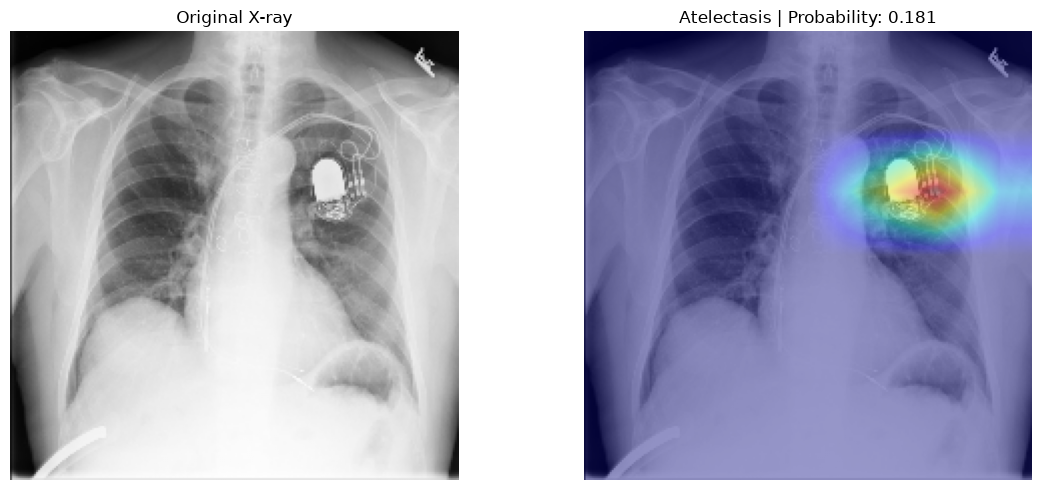

In [76]:
from medical_imaging_ai.explainability import (
    load_image_for_gradcam,
    generate_gradcam,
    visualize_gradcam
)

from medical_imaging_ai.constants import CLASSES
from medical_imaging_ai.paths import IMAGE_DIR

import numpy as np
import tensorflow as tf

# Choose an image from the validation set
sample = val_df.iloc[0]

image_path = IMAGE_DIR / sample["image_index"]

# Load preprocessed image
image_tensor = load_image_for_gradcam(image_path)

# Get model predictions
predictions = model.predict(image_tensor, verbose=0)[0]

# Select the disease with the highest predicted probability
class_index = int(np.argmax(predictions))

disease = CLASSES[class_index]
probability = float(predictions[class_index])

# Generate heatmap
heatmap = generate_gradcam(
    model,
    image_tensor,
    class_index
)

# Load original image for visualization
original = tf.io.read_file(str(image_path))
original = tf.io.decode_png(original, channels=1)
original = tf.image.resize(original, IMAGE_SIZE)
original = tf.squeeze(original).numpy()

visualize_gradcam(
    original,
    heatmap,
    disease,
    probability
)